# 1. Install packages

In [1]:
!pip -q install lime scikit-image scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# 2. Upload and display an image

Saving African_Elephant_resized-400-x-400.jpg to African_Elephant_resized-400-x-400.jpg


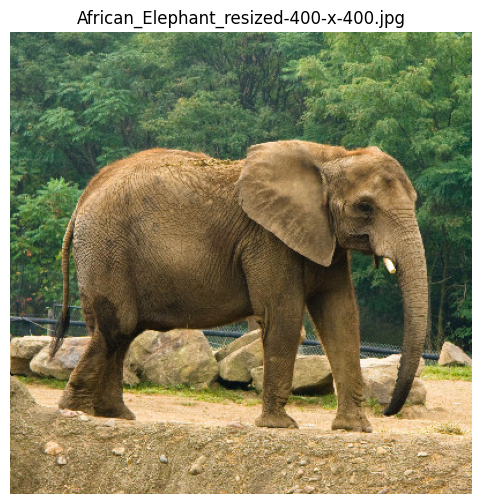

In [2]:
from google.colab import files
from PIL import Image
import io
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()  # Select an image from your computer

filename = next(iter(uploaded))
image = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")

# Keep the demo reasonably fast and make image dimensions manageable.
image.thumbnail((400, 400))

image_np = np.asarray(image).astype(np.uint8)

plt.figure(figsize=(6, 6))
plt.imshow(image_np)
plt.axis("off")
plt.title(filename)
plt.show()

# 3. Load an image classifier

This uses a pretrained ImageNet ResNet-18 model. Its predictions are just a convenient demo target; the model was not trained specifically on your image.

In [3]:
import torch
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = ResNet18_Weights.DEFAULT
classifier = resnet18(weights=weights).to(device).eval()   # NOT called `model`
preprocess = weights.transforms()
class_names = weights.meta["categories"]


def classifier_fn(images):
    """Input: a batch of RGB uint8 images. Output: class probabilities."""
    batch = torch.stack([
        preprocess(Image.fromarray(np.asarray(img).astype(np.uint8)))
        for img in images
    ]).to(device)

    with torch.no_grad():
        logits = classifier(batch)
        probs = torch.softmax(logits, dim=1)

    return probs.cpu().numpy()


original_probs = classifier_fn([image_np])[0]
top_indices = np.argsort(original_probs)[::-1][:5]

print("Top predictions:")
for i in top_indices:
    print(f"{class_names[i]:30s} {original_probs[i]:.3f}")

target_class = int(top_indices[0])
print("\nExplaining:", class_names[target_class])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 146MB/s]


Top predictions:
African elephant               0.859
Indian elephant                0.083
tusker                         0.058
Arabian camel                  0.000
triceratops                    0.000

Explaining: African elephant


In [4]:
print(type(classifier))   # must say: torchvision.models.resnet.ResNet

<class 'torchvision.models.resnet.ResNet'>


# 4. Segment the image into superpixels

Each segment is one interpretable feature: LIME-style perturbations switch whole segments off rather than changing individual pixels. The segmentation choice affects the explanation.

Number of image segments: 6


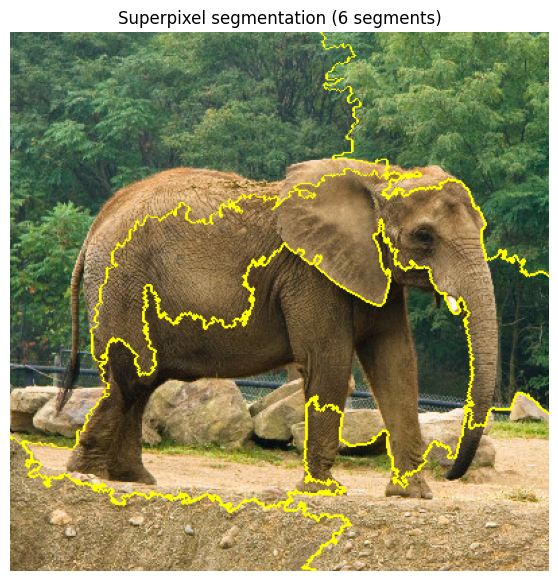

In [5]:
from skimage.segmentation import slic, mark_boundaries, relabel_sequential

segments = slic(
    image_np,
    n_segments=12,       # Try different numbers
    compactness=10,
    start_label=0,
    channel_axis=-1
)

# Relabel immediately so labels are exactly 0..num_segments-1.
# Everything downstream (masks, effects[segments], centroids) relies on this.
segments, _, _ = relabel_sequential(segments)
segments = segments.astype(int)
num_segments = int(segments.max()) + 1

assert segments.shape == image_np.shape[:2], "segments/image shape mismatch"
assert set(np.unique(segments)) == set(range(num_segments)), "labels not contiguous"

print("Number of image segments:", num_segments)

plt.figure(figsize=(7, 7))
plt.imshow(mark_boundaries(image_np, segments))
plt.axis("off")
plt.title(f"Superpixel segmentation ({num_segments} segments)")
plt.show()

In [6]:
import torch
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = ResNet18_Weights.DEFAULT
classifier = resnet18(weights=weights).to(device).eval()   # renamed
preprocess = weights.transforms()
class_names = weights.meta["categories"]

def classifier_fn(images):
    """Input: batch of RGB uint8 images. Output: class probabilities."""
    batch = torch.stack([
        preprocess(Image.fromarray(np.asarray(img).astype(np.uint8)))
        for img in images
    ]).to(device)
    with torch.no_grad():
        probs = torch.softmax(classifier(batch), dim=1)
    return probs.cpu().numpy()

# 5. Create perturbations and fit a local surrogate

Set KERNEL to "exponential", "gaussian", or "linear" to compare locality kernels. Set DEGREE to 1, 2, or 3 to compare linear, quadratic, or cubic polynomial surrogates.

For a small, readable classroom demo, keep the number of segments fairly low: polynomial models can grow quickly in complexity.

In [7]:
# ----- Settings -----
NUM_SAMPLES = 500
KERNEL_WIDTH = 0.25
RANDOM_SEED = 7
BATCH_SIZE = 32
# --------------------

rng = np.random.default_rng(RANDOM_SEED)

# Binary mask rows: 1 = keep a segment, 0 = hide it.
masks = rng.integers(0, 2, size=(NUM_SAMPLES, num_segments)).astype(float)
masks[0, :] = 1  # Include the unmodified image.

# Hidden superpixels are replaced by the mean image color.
replacement_color = image_np.mean(axis=(0, 1)).astype(np.uint8)

def make_perturbed_image(mask):
    perturbed = image_np.copy()
    for segment_id, keep in enumerate(mask):
        if keep == 0:
            perturbed[segments == segment_id] = replacement_color
    return perturbed

def predict_target(images):
    """P(target_class) for a list of images, processed in batches."""
    out = []
    for start in range(0, len(images), BATCH_SIZE):
        probs = classifier_fn(images[start:start + BATCH_SIZE])
        out.extend(probs[:, target_class])
    return np.asarray(out)

perturbed_images = [make_perturbed_image(m) for m in masks]
y = predict_target(perturbed_images)

# Cosine distance of each mask from the all-ones mask (the original image).
original_mask = np.ones(num_segments)
dot = masks @ original_mask
denom = np.linalg.norm(masks, axis=1) * np.linalg.norm(original_mask)
similarity = np.divide(dot, denom, out=np.zeros_like(dot), where=denom > 0)
distances = 1.0 - similarity

def kernel_weights(distances, kernel, width):
    width = max(float(width), 1e-8)
    if kernel == "exponential":      # Laplacian shape: exp(-d/w)
        return np.exp(-distances / width)
    elif kernel == "gaussian":       # exp(-d^2 / (2 w^2))
        return np.exp(-0.5 * (distances / width) ** 2)
    elif kernel == "linear":         # hard cutoff at distance = width
        return np.clip(1.0 - distances / width, 0.0, 1.0)
    else:
        raise ValueError("Choose 'exponential', 'gaussian', or 'linear'.")

# ----- Quick diagnostics -----
print("Samples:", NUM_SAMPLES, "| segments:", num_segments)
print(f"P(target) on original image: {y[0]:.3f}")
print(f"P(target) range over perturbations: {y.min():.3f} .. {y.max():.3f}")
print(f"Distance range: {distances.min():.3f} .. {distances.max():.3f}")
for k in ["exponential", "gaussian", "linear"]:
    w = kernel_weights(distances, k, KERNEL_WIDTH)
    print(f"{k:12s} effective sample size: {w.sum()**2 / (w**2).sum():6.1f}")

Samples: 500 | segments: 6
P(target) on original image: 0.859
P(target) range over perturbations: 0.000 .. 0.866
Distance range: -0.000 .. 1.000
exponential  effective sample size:  379.0
gaussian     effective sample size:  385.5
linear       effective sample size:  135.0


True P(target) on original image: 0.859

degree       kernel features   eff.N  local R2  pred(orig)  abs.err
----------------------------------------------------------------------
     1  exponential        6   379.0     0.836       0.997    0.137
     1     gaussian        6   385.5     0.831       1.016    0.156
     1       linear        6   135.0     0.647       0.879    0.020
     2  exponential       27   379.0     0.885       0.960    0.101
     2     gaussian       27   385.5     0.895       0.962    0.103
     2       linear       27   135.0     0.866       0.896    0.037
     3  exponential       83   379.0     0.983       0.877    0.018
     3     gaussian       83   385.5     0.988       0.873    0.014
     3       linear       83   135.0     0.965       0.882    0.022


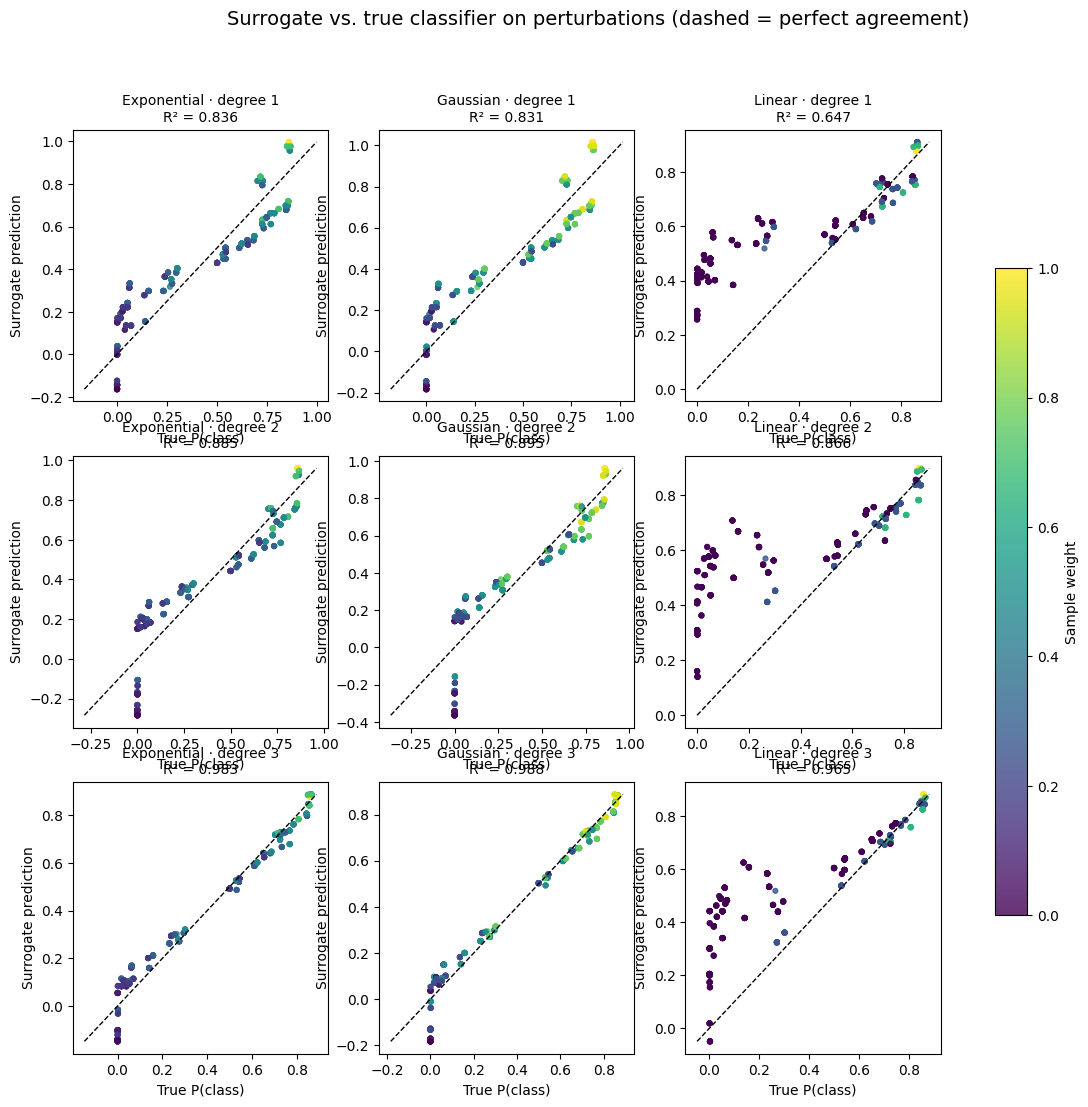

In [8]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

degrees = [1, 2, 3]
kernels = ["exponential", "gaussian", "linear"]
RIDGE_ALPHA = 1.0

results = {}

for degree in degrees:
    # Feature expansion depends only on the degree, so build it once per degree.
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(masks)

    for kernel in kernels:
        w = kernel_weights(distances, kernel, KERNEL_WIDTH)

        # `surrogate` is a new object each time (never called `model` or `classifier`)
        surrogate = Ridge(alpha=RIDGE_ALPHA)
        surrogate.fit(X_poly, y, sample_weight=w)

        pred = surrogate.predict(X_poly)

        # Weighted local R^2 on the generated perturbations
        w_mean = np.average(y, weights=w)
        ss_res = np.sum(w * (y - pred) ** 2)
        ss_tot = np.sum(w * (y - w_mean) ** 2)
        local_r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

        # Prediction of the surrogate at the unmodified image (all segments visible)
        full_pred = surrogate.predict(poly.transform(np.ones((1, num_segments))))[0]

        results[(degree, kernel)] = {
            "model": surrogate,        # key name matches what cell 6 reads
            "poly": poly,
            "weights": w,
            "r2": local_r2,
            "full_pred": full_pred,
            "n_features": X_poly.shape[1],
            "eff_n": w.sum() ** 2 / (w ** 2).sum(),
        }

# ----- Summary table -----
true_full = y[0]
print(f"True P(target) on original image: {true_full:.3f}\n")
print(f"{'degree':>6} {'kernel':>12} {'features':>8} {'eff.N':>7} "
      f"{'local R2':>9} {'pred(orig)':>11} {'abs.err':>8}")
print("-" * 70)
for degree in degrees:
    for kernel in kernels:
        r = results[(degree, kernel)]
        print(f"{degree:>6} {kernel:>12} {r['n_features']:>8} {r['eff_n']:>7.1f} "
              f"{r['r2']:>9.3f} {r['full_pred']:>11.3f} "
              f"{abs(r['full_pred'] - true_full):>8.3f}")

# ----- 3x3 plot: surrogate predictions vs. true classifier on all perturbations -----
fig, axes = plt.subplots(len(degrees), len(kernels), figsize=(14, 12), squeeze=False)
for r_i, degree in enumerate(degrees):
    for c_i, kernel in enumerate(kernels):
        res = results[(degree, kernel)]
        pred = res["model"].predict(res["poly"].transform(masks))
        ax = axes[r_i, c_i]
        sc = ax.scatter(y, pred, c=res["weights"], cmap="viridis", s=12, alpha=0.8)
        lo, hi = min(y.min(), pred.min()), max(y.max(), pred.max())
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set_title(f"{kernel.capitalize()} · degree {degree}\nR² = {res['r2']:.3f}",
                     fontsize=10)
        ax.set_xlabel("True P(class)")
        ax.set_ylabel("Surrogate prediction")
fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.7, label="Sample weight")
fig.suptitle("Surrogate vs. true classifier on perturbations "
             "(dashed = perfect agreement)", fontsize=14)
plt.show()

# 6. Visualize the local approximation and influential regions

With a polynomial surrogate, there are interaction terms as well as individual segment terms. The bars below show first-order coefficients only; they are not the full effect of a segment when interactions are present. In particular, for degree 2 or 3, don’t interpret them as a complete ranking of feature importance.

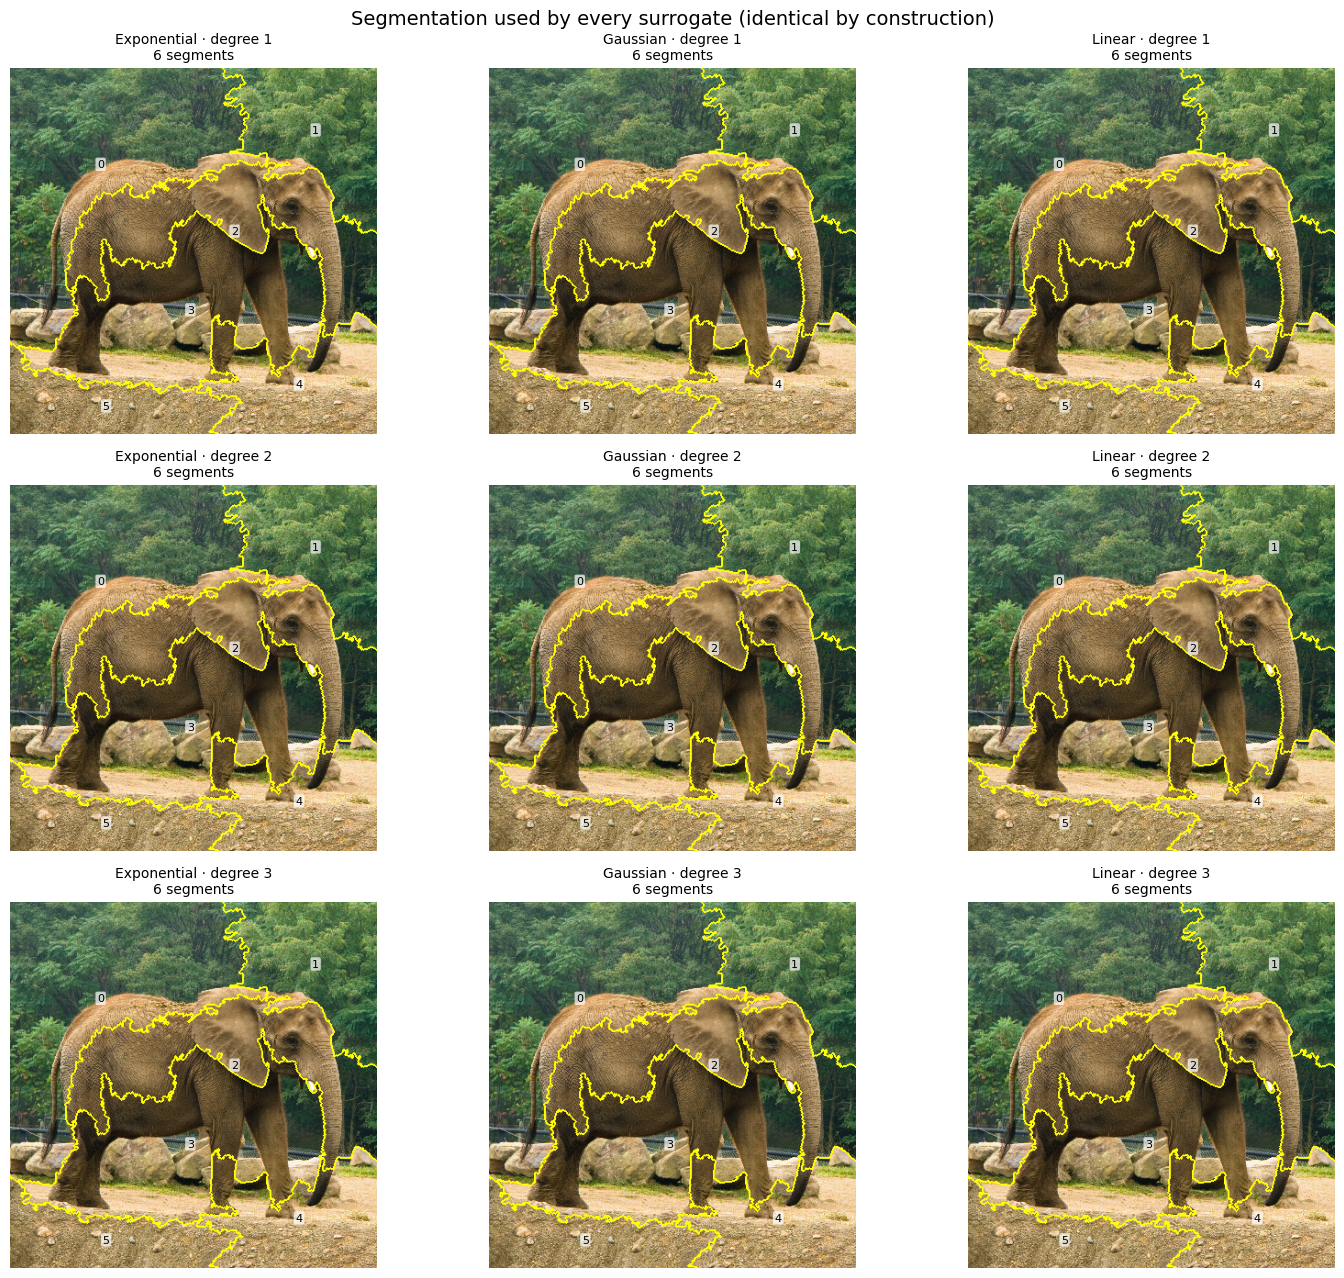

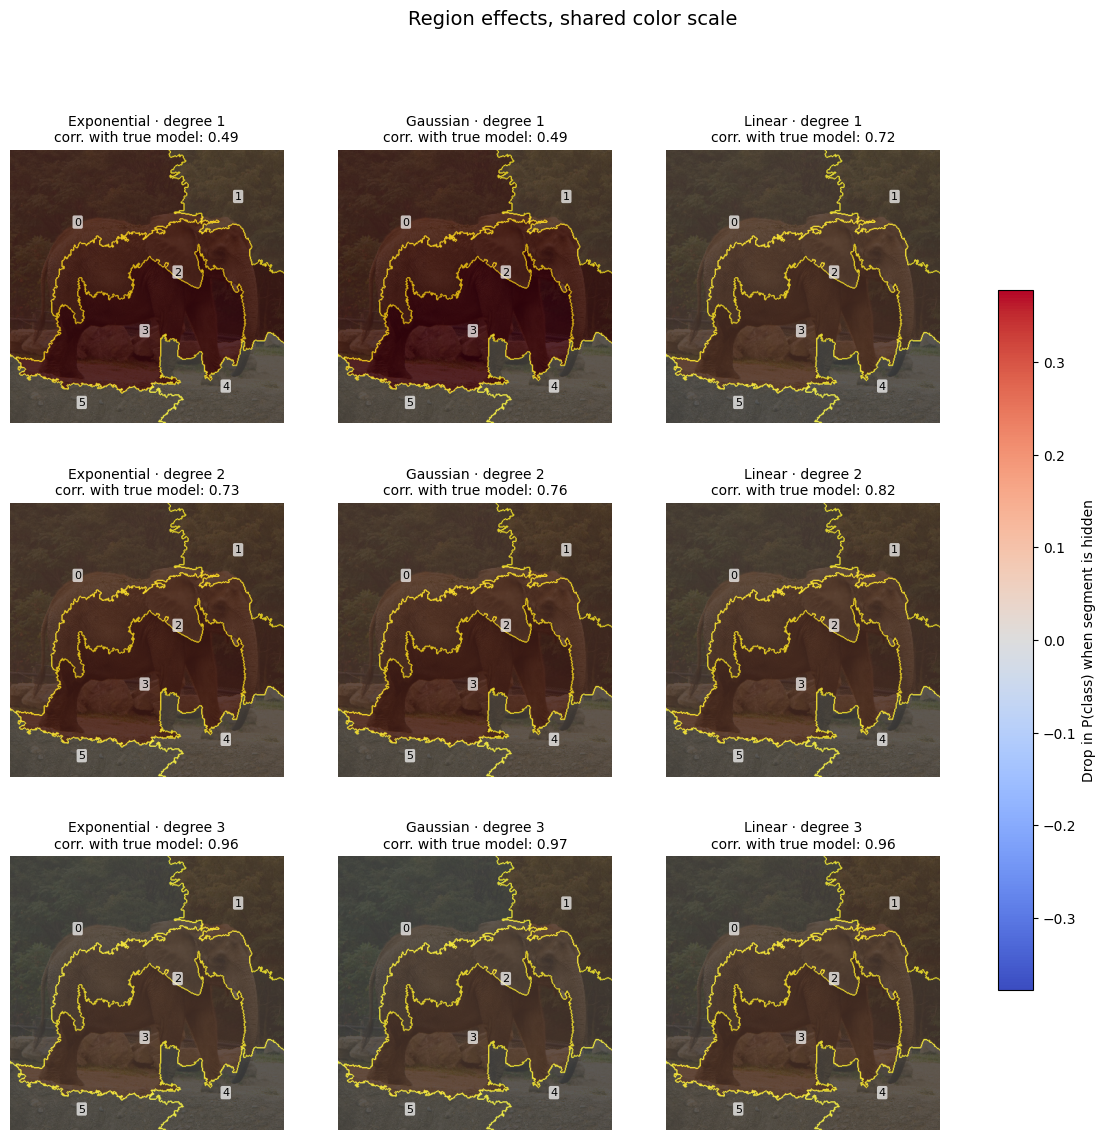

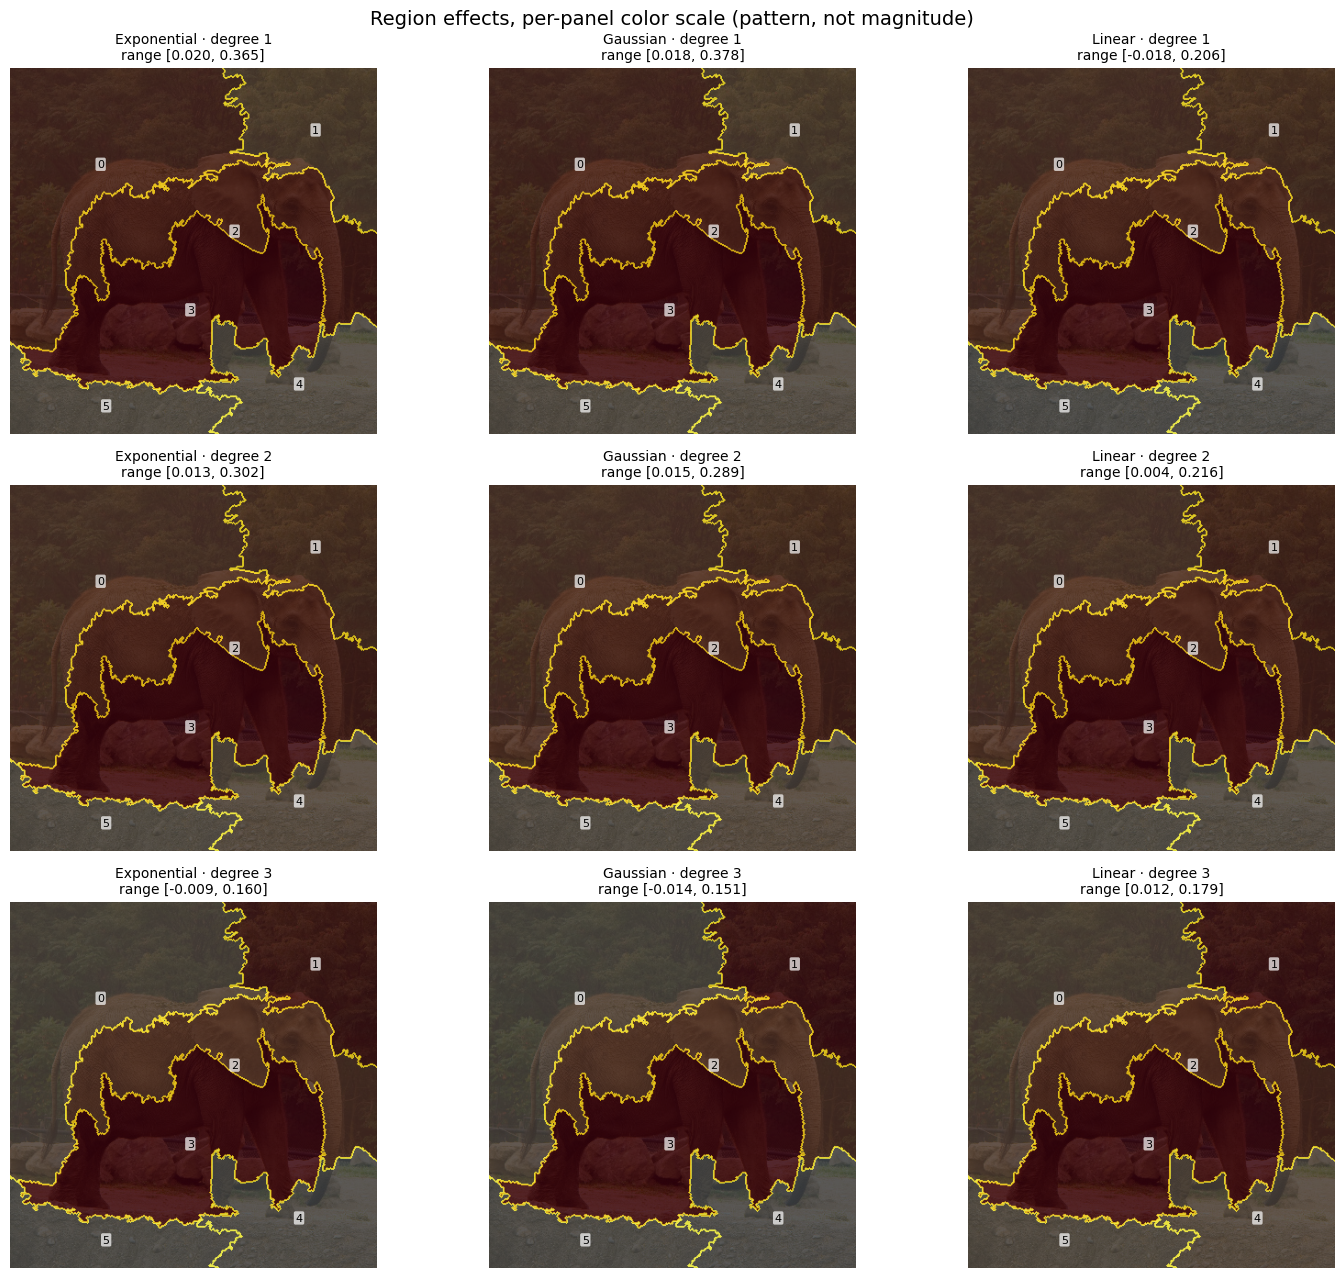

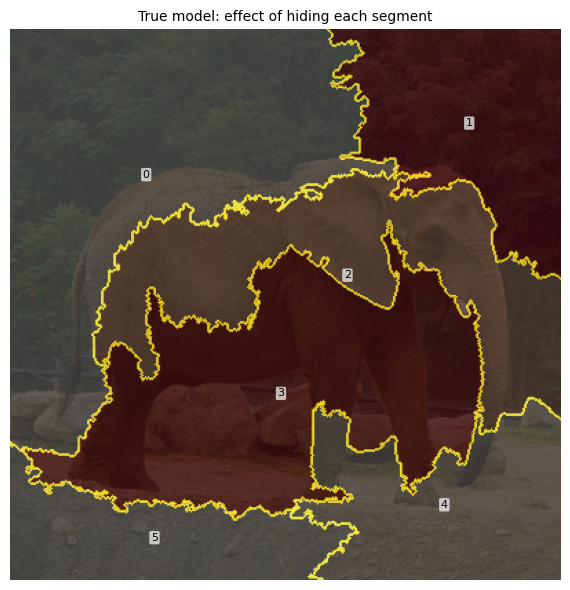

Seg |  true  | exp-d1 | gau-d1 | lin-d1 | exp-d2 | gau-d2 | lin-d2 | exp-d3 | gau-d3 | lin-d3
---------------------------------------------------------------------------------------------
  0 | +0.004 | +0.278 | +0.290 | +0.127 | +0.179 | +0.170 | +0.116 | +0.036 | +0.027 | +0.057
  1 | +0.143 | +0.163 | +0.167 | +0.134 | +0.201 | +0.202 | +0.175 | +0.151 | +0.148 | +0.175
  2 | +0.052 | +0.314 | +0.325 | +0.155 | +0.244 | +0.223 | +0.170 | +0.094 | +0.084 | +0.124
  3 | +0.133 | +0.365 | +0.378 | +0.206 | +0.302 | +0.289 | +0.216 | +0.160 | +0.151 | +0.179
  4 | +0.009 | +0.020 | +0.020 | -0.013 | +0.040 | +0.039 | +0.012 | -0.008 | -0.014 | +0.025
  5 | -0.007 | +0.020 | +0.018 | -0.018 | +0.013 | +0.015 | +0.004 | -0.009 | -0.007 | +0.012

Correlation with true effects (higher = more faithful):
  degree 1: exponential=0.49, gaussian=0.49, linear=0.72
  degree 2: exponential=0.73, gaussian=0.76, linear=0.82
  degree 3: exponential=0.96, gaussian=0.97, linear=0.96


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from skimage.segmentation import mark_boundaries, relabel_sequential

# ------------------------------------------------------------------
# 0. Safety: make segment labels exactly 0..K-1 so effects[segments] works
#    (slic can skip labels; relabel_sequential removes gaps)
# ------------------------------------------------------------------
segments_seq, _, _ = relabel_sequential(segments)
if segments_seq.max() + 1 != num_segments:
    print(f"Warning: num_segments was {num_segments}, "
          f"actual is {segments_seq.max() + 1}. Re-run Steps 3-4 if this differs.")
segments_vis = segments_seq.astype(int)   # for plotting only; same partition as `segments`

# ------------------------------------------------------------------
# 1. Helpers: boundary image and segment centroids
# ------------------------------------------------------------------
boundary_img = mark_boundaries(image_np.astype(np.float32) / 255.0,
                               segments_vis, color=(1, 1, 0), mode="thick")

centroids = {}
for seg_id in range(num_segments):
    ys, xs = np.where(segments_vis == seg_id)
    centroids[seg_id] = (xs.mean(), ys.mean())

def draw_effect_panel(ax, effects, limit, title):
    """Overlay per-segment effects on the image with a symmetric diverging scale."""
    limit = max(float(limit), 1e-8)
    norm = mcolors.TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
    rgba = plt.get_cmap("coolwarm")(norm(effects[segments_vis]))
    rgba[..., 3] = 0.6
    ax.imshow(image_np)
    ax.imshow(rgba)
    ax.imshow(mark_boundaries(np.zeros_like(image_np), segments_vis,
                              color=(1, 1, 0), mode="thick"), alpha=0.6)
    for seg_id, (cx, cy) in centroids.items():
        ax.text(cx, cy, str(seg_id), fontsize=8, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))
    ax.set_title(title, fontsize=10)
    ax.axis("off")

# ------------------------------------------------------------------
# 2. Surrogate region effects: P(all visible) - P(this segment hidden)
# ------------------------------------------------------------------
all_visible = np.ones((1, num_segments))
region_effects = {}
for degree in degrees:
    for kernel in kernels:
        res = results[(degree, kernel)]
        sur, poly = res["model"], res["poly"]
        full = sur.predict(poly.transform(all_visible))[0]
        eff = np.zeros(num_segments)
        for s in range(num_segments):
            m = all_visible.copy()
            m[0, s] = 0.0
            eff[s] = full - sur.predict(poly.transform(m))[0]
        region_effects[(degree, kernel)] = eff

# ------------------------------------------------------------------
# 3. Ground truth: hide each segment, ask the REAL classifier
# ------------------------------------------------------------------
original_prob = y[0]   # mask 0 is the unmodified image
ablated = []
for s in range(num_segments):
    m = np.ones(num_segments)
    m[s] = 0.0
    ablated.append(make_perturbed_image(m))
true_effects = original_prob - predict_target(ablated)

# ------------------------------------------------------------------
# FIGURE A: segmentation check
# ------------------------------------------------------------------
fig, axes = plt.subplots(len(degrees), len(kernels), figsize=(15, 13), squeeze=False)
for r, degree in enumerate(degrees):
    for c, kernel in enumerate(kernels):
        ax = axes[r, c]
        ax.imshow(boundary_img)
        for seg_id, (cx, cy) in centroids.items():
            ax.text(cx, cy, str(seg_id), fontsize=8, ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))
        ax.set_title(f"{kernel.capitalize()} · degree {degree}\n{num_segments} segments",
                     fontsize=10)
        ax.axis("off")
fig.suptitle("Segmentation used by every surrogate (identical by construction)", fontsize=14)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# FIGURE B: region effects, SHARED color scale (magnitudes comparable)
# ------------------------------------------------------------------
shared_limit = max(max(np.abs(e).max() for e in region_effects.values()),
                   np.abs(true_effects).max())
fig, axes = plt.subplots(len(degrees), len(kernels), figsize=(15, 13), squeeze=False)
for r, degree in enumerate(degrees):
    for c, kernel in enumerate(kernels):
        e = region_effects[(degree, kernel)]
        corr = np.corrcoef(e, true_effects)[0, 1] if np.std(e) > 0 else np.nan
        draw_effect_panel(axes[r, c], e, shared_limit,
                          f"{kernel.capitalize()} · degree {degree}\n"
                          f"corr. with true model: {corr:.2f}")

sm = plt.cm.ScalarMappable(
    norm=mcolors.TwoSlopeNorm(vmin=-shared_limit, vcenter=0, vmax=shared_limit),
    cmap="coolwarm")


sm.set_array([])
fig.colorbar(sm, ax=axes.ravel().tolist(), shrink=0.7,
             label="Drop in P(class) when segment is hidden")
fig.suptitle("Region effects, shared color scale", fontsize=14)
plt.show()

# ------------------------------------------------------------------
# FIGURE C: per-panel color scale (pattern, not magnitude)
# ------------------------------------------------------------------
fig, axes = plt.subplots(len(degrees), len(kernels), figsize=(15, 13), squeeze=False)
for r, degree in enumerate(degrees):
    for c, kernel in enumerate(kernels):
        e = region_effects[(degree, kernel)]
        draw_effect_panel(axes[r, c], e, np.abs(e).max(),
                          f"{kernel.capitalize()} · degree {degree}\n"
                          f"range [{e.min():.3f}, {e.max():.3f}]")
fig.suptitle("Region effects, per-panel color scale (pattern, not magnitude)", fontsize=14)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# FIGURE D: ground truth from the real classifier
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 6))
draw_effect_panel(ax, true_effects, np.abs(true_effects).max(),
                  "True model: effect of hiding each segment")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# Numeric comparison table
# ------------------------------------------------------------------
header = "Seg |  true  | " + " | ".join(f"{k[:3]}-d{d}" for d in degrees for k in kernels)
print(header)
print("-" * len(header))
for s in range(num_segments):
    row = " | ".join(f"{region_effects[(d, k)][s]:+.3f}" for d in degrees for k in kernels)
    print(f"{s:3d} | {true_effects[s]:+.3f} | {row}")

print("\nCorrelation with true effects (higher = more faithful):")
for d in degrees:
    print(f"  degree {d}: " + ", ".join(
        f"{k}={np.corrcoef(region_effects[(d, k)], true_effects)[0, 1]:.2f}" for k in kernels))